# Chapter 1: Sector Diversification

*Is sector diversification real, or does it fail when it matters most?*

Spreading money across sectors feels safe: if one crashes, the others should hold. This chapter checks whether sectors really move independently, with two questions:

- **Returns:** do two sectors go up and down on the same days? (correlation of daily sector returns)
- **Volatility:** do they become risky at the same time? (correlation of 60-day sector volatility)

Both are measured over three windows: the **full sample**, the **last 20 years** and the **last 5 years**. Each sector is summarised by its **average correlation with the other sectors**: the lower it is, the more independently the sector moves, so the better it diversifies.

- **Input:** `data_processed/stocks_sect.parquet` (from `preparing_sectors.ipynb`).
- **Outputs:**
  - `website/content/chapter1.json`: the data behind the two Chapter 1 charts on the website;
  - `website/figures/chapter1/`: static versions of those charts.

**Contents**
1. Setup
2. Sector series
3. Time windows
4. Correlation matrices
5. Which sectors diversify? (website chart 1)
6. Every pair of sectors (website chart 2)
7. Website data
8. Numbers quoted in the website text

## 1. Setup

In [1]:
import json
from pathlib import Path

import pandas as pd

from src.chapters.chapter1 import (
    avg_corr,
    cluster_order,
    corr_matrix,
    make_windows,
    mean_pair_corr,
    plot_corr_heatmaps,
    plot_avg_corr_dots,
    site_json,
)
from src.utils.figures import save_figure
from src.utils.sector_panel import first_date_all_sectors, sector_returns, sector_series, stocks_per_sector

PROCESSED_DIR = Path("data_processed")
SITE_JSON = Path("website/content/chapter1.json")
FIG_SECTION = "chapter1"

END_DATE = "2020-04-01"                                 # last date of the price data
WINDOW_STARTS = {"20y": "2000-04-01", "5y": "2015-04-01"}
MIN_STOCKS_PER_SECTOR = 5   # the full sample starts when every sector has at least 5 stocks
MIN_OVERLAP = 2 * 252       # at least 2 years of common data to report a correlation
VOL_COLUMN = "WeightedVol60"

## 2. Sector series

One daily series per sector, from the stocks of `stocks_sect.parquet`:

- **return:** dollar-volume weighted average of its stocks' daily returns;
- **volatility:** dollar-volume weighted average of its stocks' 60-day volatility.

The weights are built in `preparing_sectors.ipynb` (each stock's share of the sector's dollar volume that day).

In [2]:
stocks_sect = pd.read_parquet(
    PROCESSED_DIR / "stocks_sect.parquet",
    columns=["Date", "Symbol", "Sector", "Return", "Weight", VOL_COLUMN],
)

returns = sector_returns(stocks_sect)
volatility = sector_series(stocks_sect, VOL_COLUMN)
stock_counts = stocks_per_sector(stocks_sect)

sectors = sorted(returns.columns)
returns, volatility, stock_counts = returns[sectors], volatility[sectors], stock_counts[sectors]
print(f"{len(sectors)} sectors, {returns.index.min().date()} → {returns.index.max().date()}")
stock_counts.iloc[-1].rename("stocks on the last day").to_frame()

11 sectors, 1962-01-02 → 2020-04-01


,stocks on the last day
Sector,
Basic Materials,143
Communication Services,116
Consumer Cyclical,288
Consumer Defensive,124
Energy,134
Financial Services,733
Healthcare,405
Industrials,338
Real Estate,168


## 3. Time windows

The **full sample** starts on the first day where every sector has at least `MIN_STOCKS_PER_SECTOR` stocks, so that each sector series is an average of several companies rather than one or two. The two other windows cover the last 20 and 5 years of data.

In [3]:
windows = make_windows(first_date_all_sectors(stock_counts, MIN_STOCKS_PER_SECTOR), END_DATE, WINDOW_STARTS)
windows["days"] = [len(returns.loc[r.start:r.end]) for r in windows.itertuples()]
windows

,start,end,name,label,days
key,,,,,
full,1980-03-19,2020-04-01,Full sample,Full sample (1980–2020),10096
20y,2000-04-01,2020-04-01,Last 20 years,Last 20 years (2000–2020),5031
5y,2015-04-01,2020-04-01,Last 5 years,Last 5 years (2015–2020),1260


## 4. Correlation matrices

Pearson correlation between every pair of sectors, for each metric and window (at least `MIN_OVERLAP` common days per pair).

In [4]:
series = {"returns": returns, "volatility": volatility}
mats = {
    metric: {w: corr_matrix(s, r.start, r.end, MIN_OVERLAP) for w, r in windows.iterrows()}
    for metric, s in series.items()
}

pd.DataFrame(
    {metric: {windows.loc[w, "label"]: mean_pair_corr(m) for w, m in by_w.items()} for metric, by_w in mats.items()}
).round(3).rename_axis("average pair correlation")

,returns,volatility
average pair correlation,,
Full sample (1980–2020),0.456,0.711
Last 20 years (2000–2020),0.511,0.771
Last 5 years (2015–2020),0.540,0.757


## 5. Which sectors diversify? (website chart 1)

Each dot is a sector's average correlation with the other sectors in one window. Further left means more independent, so a better diversifier. Comparing the three dots of a sector shows whether that changed over time.

Saved website/figures/chapter1/avg_corr_returns.png
Saved website/figures/chapter1/avg_corr_volatility.png


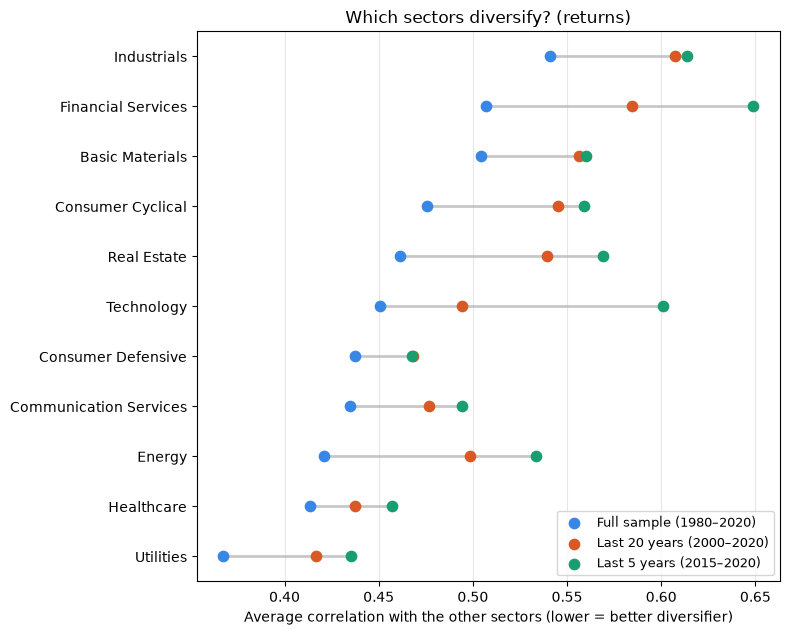

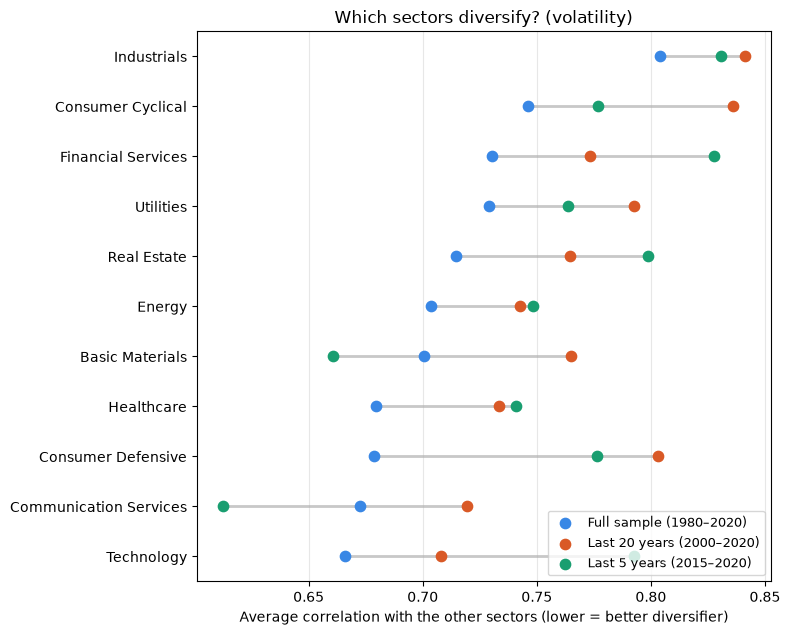

In [5]:
avgs = {metric: {w: avg_corr(m) for w, m in by_w.items()} for metric, by_w in mats.items()}

for metric in ["returns", "volatility"]:
    fig = plot_avg_corr_dots(avgs[metric], windows, f"Which sectors diversify? ({metric})")
    print("Saved", save_figure(fig, FIG_SECTION, f"avg_corr_{metric}"))

## 6. Every pair of sectors (website chart 2)

Lower-triangle heatmaps, with sectors ordered by hierarchical clustering on the full-sample matrix so that sectors that move alike form blocks. The last panel shows the change between the last 5 years and the full sample.

Saved website/figures/chapter1/heatmaps_returns.png
Saved website/figures/chapter1/heatmaps_volatility.png


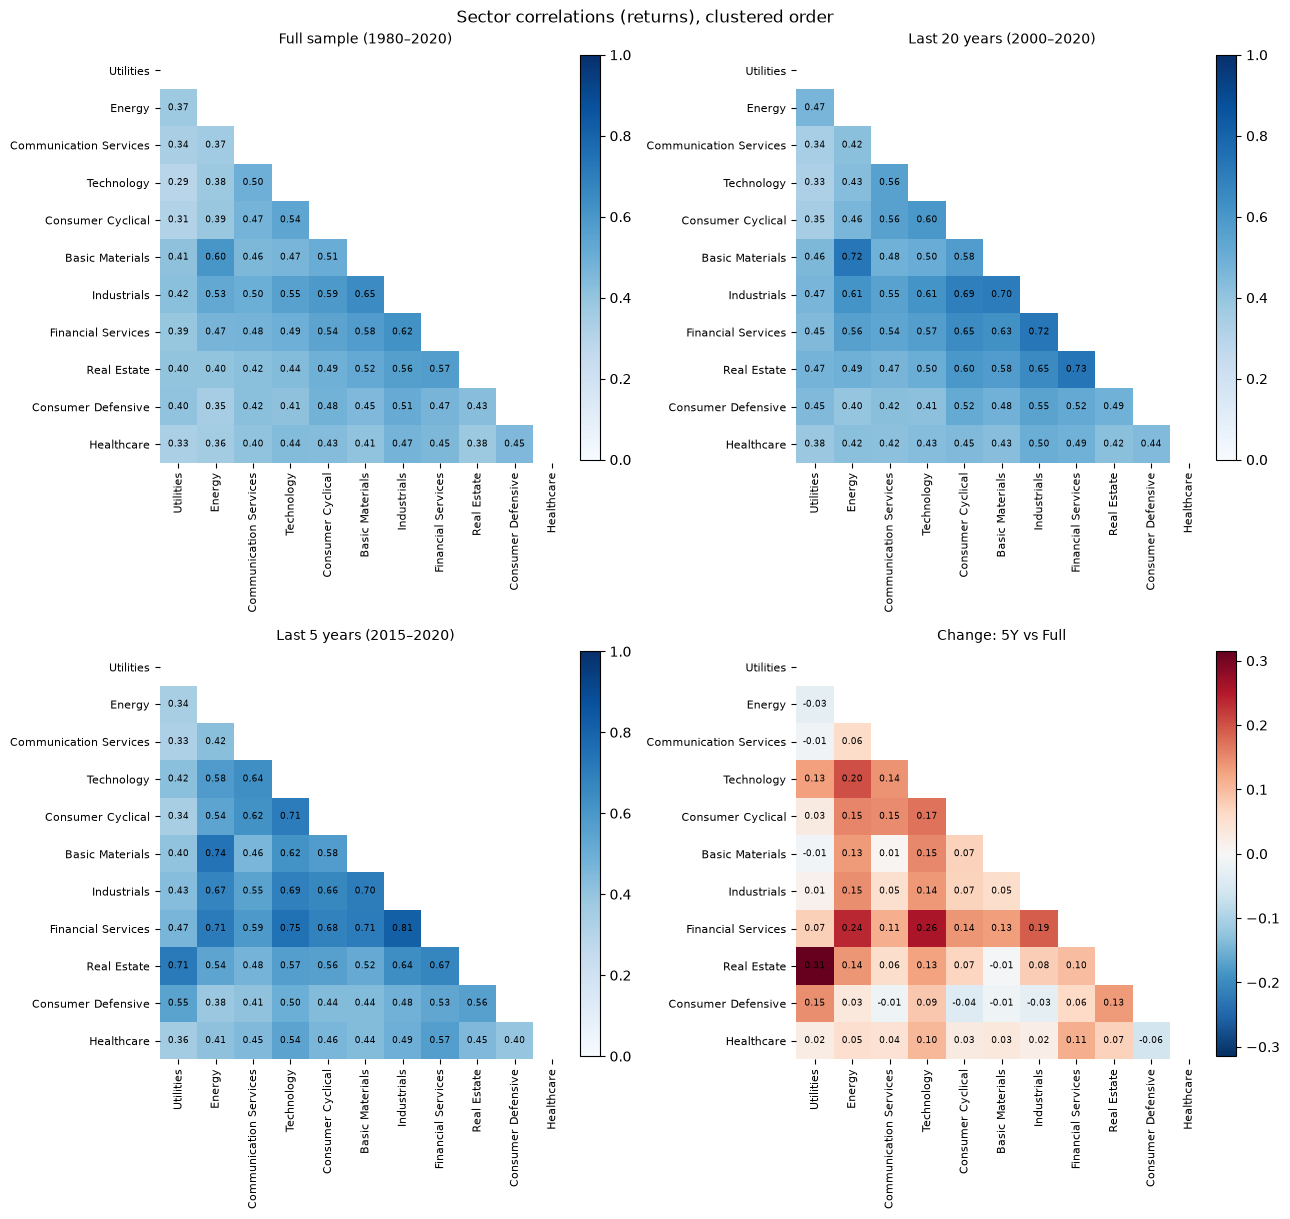

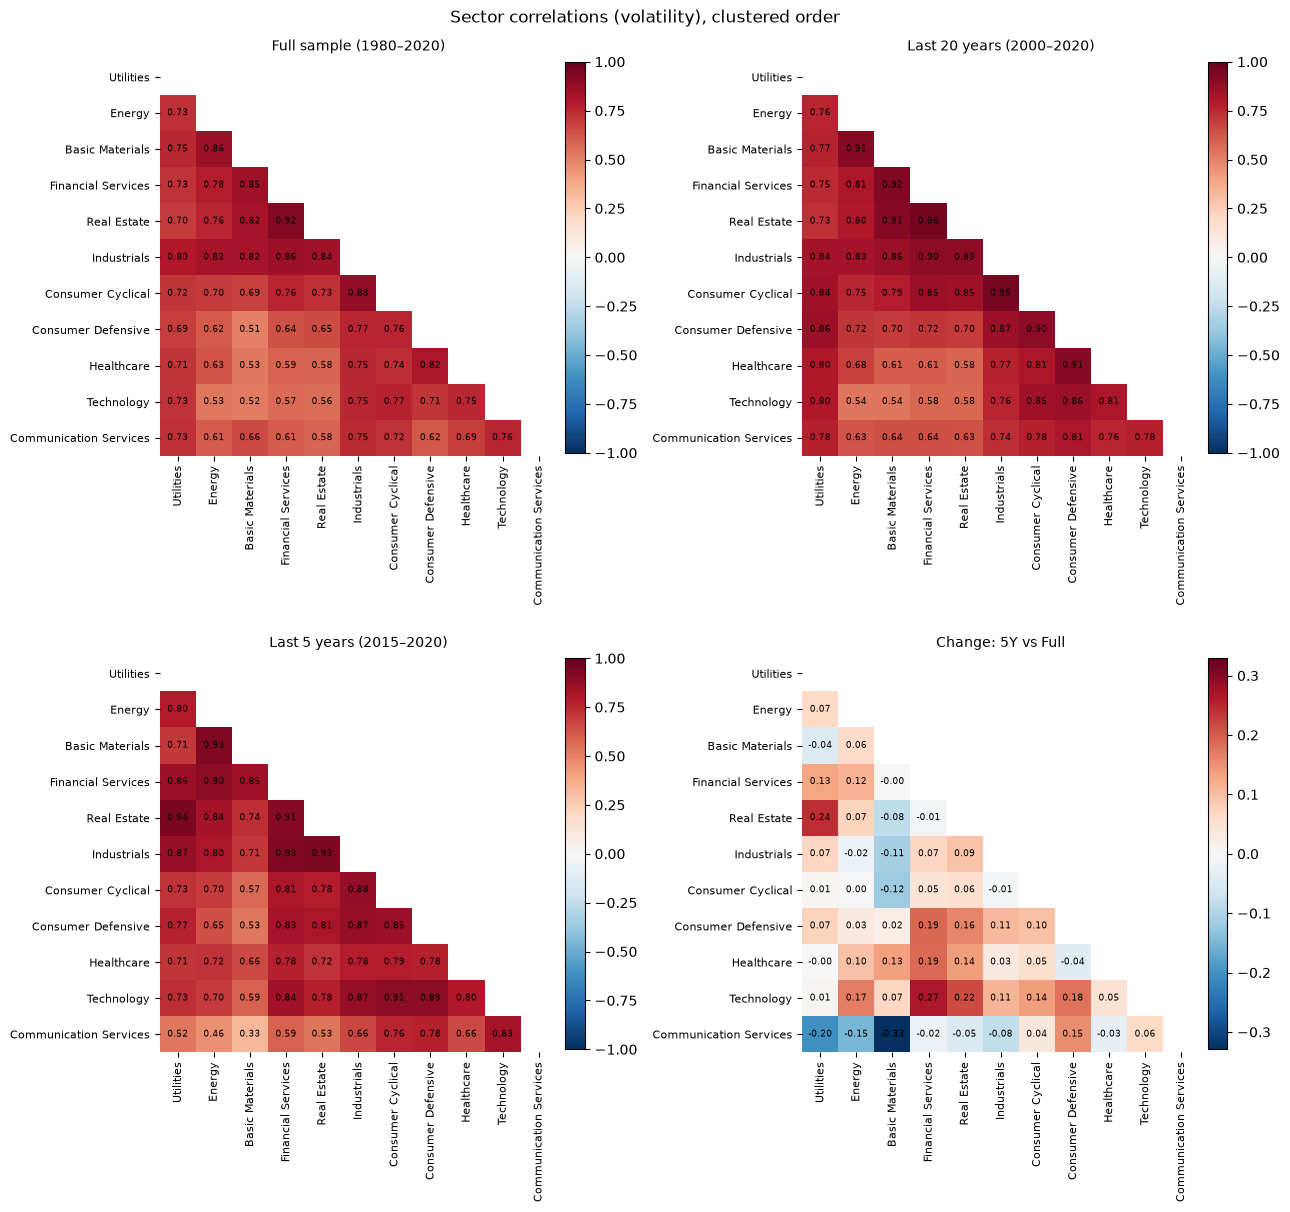

In [6]:
for metric in ["returns", "volatility"]:
    order = cluster_order(mats[metric]["full"])
    fig = plot_corr_heatmaps(mats[metric], windows, order, metric)
    print("Saved", save_figure(fig, FIG_SECTION, f"heatmaps_{metric}"))

## 7. Website data

`website/content/chapter1.json` feeds the two interactive charts of Chapter 1 (`website/chapter1.js`).

In [7]:
data = site_json(sectors, windows, mats)
SITE_JSON.write_text(json.dumps(data, ensure_ascii=False, separators=(",", ":")))
print(f"Saved {SITE_JSON} ({SITE_JSON.stat().st_size / 1024:.1f} KB)")

Saved website/content/chapter1.json (4.6 KB)


## 8. Numbers quoted in the website text

The Chapter 1 text in `website/index.html` quotes the values below. After a new run, update the text with them.

In [8]:
def pair(metric, a, b):
    return {windows.loc[w, "label"]: round(m.loc[a, b], 2) for w, m in mats[metric].items()}

quoted_pairs = {
    ("returns", "Financial Services", "Consumer Cyclical"): pair("returns", "Financial Services", "Consumer Cyclical"),
    ("returns", "Financial Services", "Energy"): pair("returns", "Financial Services", "Energy"),
    ("returns", "Financial Services", "Technology"): pair("returns", "Financial Services", "Technology"),
    ("returns", "Healthcare", "Utilities"): pair("returns", "Healthcare", "Utilities"),
    ("volatility", "Energy", "Basic Materials"): pair("volatility", "Energy", "Basic Materials"),
    ("volatility", "Financial Services", "Energy"): pair("volatility", "Financial Services", "Energy"),
    ("volatility", "Financial Services", "Technology"): pair("volatility", "Financial Services", "Technology"),
}
pd.DataFrame(quoted_pairs).T.rename_axis(["metric", "sector A", "sector B"])

Full sample (1980–2020)  \
metric     sector A           sector B                                     
returns    Financial Services Consumer Cyclical                     0.54   
                              Energy                                0.47   
                              Technology                            0.49   
           Healthcare         Utilities                             0.33   
volatility Energy             Basic Materials                       0.86   
           Financial Services Energy                                0.78   
                              Technology                            0.57   

                                                 Last 20 years (2000–2020)  \
metric     sector A           sector B                                       
returns    Financial Services Consumer Cyclical                       0.65   
                              Energy                                  0.56   
                              Technology                              0.57   
           Healthcare         Utilities                               0.38   
volatility Energy             Basic Materials                         0.91   
           Financial Services Energy                                  0.81   
                              Technology                              0.58   

                                                 Last 5 years (2015–2020)  
metric     sector A           sector B                                     
returns    Financial Services Consumer Cyclical                      0.68  
                              Energy                                 0.71  
                              Technology                             0.75  
           Healthcare         Utilities                              0.36  
volatility Energy             Basic Materials                        0.93  
           Financial Services Energy                                 0.90  
                              Technology                             0.84

In [9]:
pd.concat(
    {metric: pd.DataFrame({windows.loc[w, "label"]: a for w, a in by_w.items()}) for metric, by_w in avgs.items()},
    axis=1,
).round(2).rename_axis("average correlation with the other sectors")

returns  \
                                           Full sample (1980–2020)   
average correlation with the other sectors                           
Basic Materials                                               0.50   
Communication Services                                        0.43   
Consumer Cyclical                                             0.48   
Consumer Defensive                                            0.44   
Energy                                                        0.42   
Financial Services                                            0.51   
Healthcare                                                    0.41   
Industrials                                                   0.54   
Real Estate                                                   0.46   
Technology                                                    0.45   
Utilities                                                     0.37   

                                                                      \
                                           Last 20 years (2000–2020)   
average correlation with the other sectors                             
Basic Materials                                                 0.56   
Communication Services                                          0.48   
Consumer Cyclical                                               0.55   
Consumer Defensive                                              0.47   
Energy                                                          0.50   
Financial Services                                              0.58   
Healthcare                                                      0.44   
Industrials                                                     0.61   
Real Estate                                                     0.54   
Technology                                                      0.49   
Utilities                                                       0.42   

                                                                     \
                                           Last 5 years (2015–2020)   
average correlation with the other sectors                            
Basic Materials                                                0.56   
Communication Services                                         0.49   
Consumer Cyclical                                              0.56   
Consumer Defensive                                             0.47   
Energy                                                         0.53   
Financial Services                                             0.65   
Healthcare                                                     0.46   
Industrials                                                    0.61   
Real Estate                                                    0.57   
Technology                                                     0.60   
Utilities                                                      0.44   

                                                        volatility  \
                                           Full sample (1980–2020)   
average correlation with the other sectors                           
Basic Materials                                               0.70   
Communication Services                                        0.67   
Consumer Cyclical                                             0.75   
Consumer Defensive                                            0.68   
Energy                                                        0.70   
Financial Services                                            0.73   
Healthcare                                                    0.68   
Industrials                                                   0.80   
Real Estate                                                   0.71   
Technology                                                    0.67   
Utilities                                                     0.73   

                                                                      \
                     